## **Consolidated Theoretical Model of the Magnetic Properties of $Al_{1-x}Mn_xN$ (Wurtzite)**

### 1. Fundamental Equations (Spin-Wave Model)

The calculation is based on Spin Wave Theory ($T^{3/2}$ law), adapted for the wurtzite crystal structure of AlN.


* Wurtzite Unit Cell Volume: $V_{cell} = \frac{\sqrt{3}}{2} a^2 c$
* Curie Temperature ($T_C$): $T_{c} = \left(x \frac{2JS}{k_{B}}\right) \left(\frac{n S V_{cell}}{0.0587}\right)^{\frac{2}{3}}$
* Reduced Magnetization: $\frac{M_{S}(T)}{M_{S}(0)} = 1 - \left(\frac{T}{T_c}\right)^{\frac{3}{2}}$
* Heat Capacity: $C_{magnon} \propto T^{3/2}$

### **Simulation**

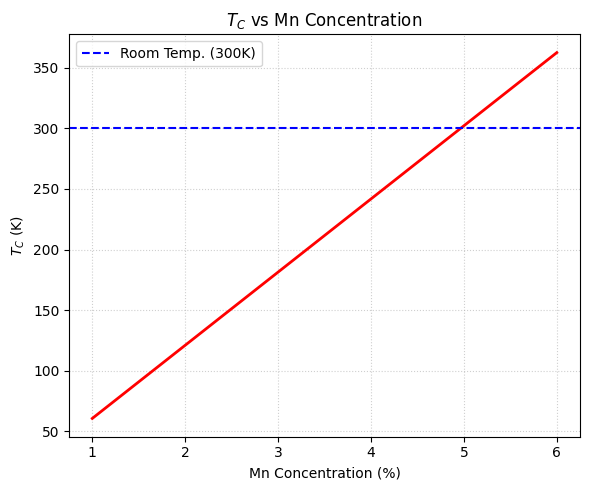

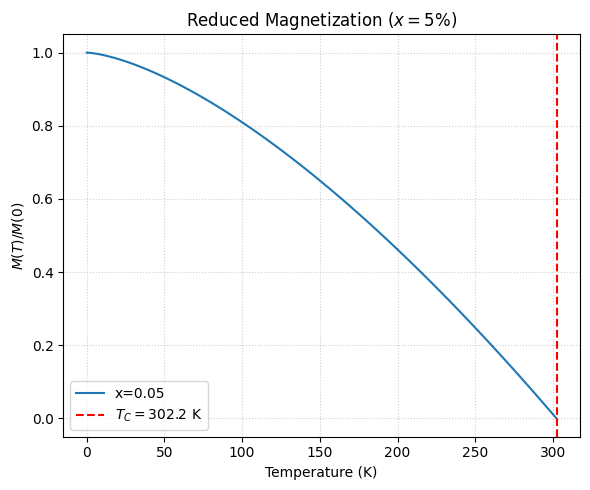

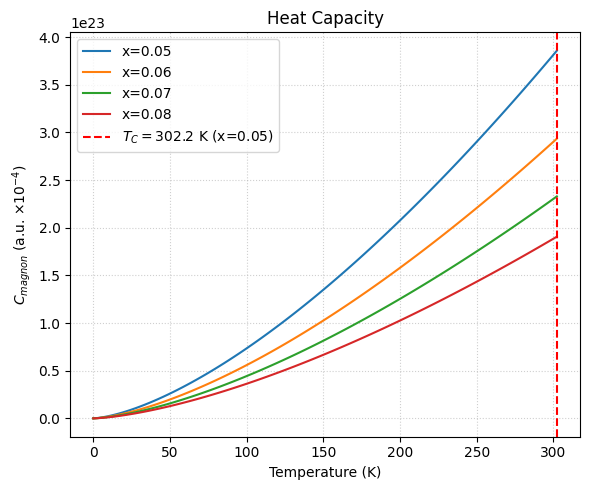

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import os

# ==========================================
# PHYSICAL PARAMETERS OF AlN:Mn (WURTZITE)
# ==========================================
# Constants
kB = 0.08625      # Boltzmann constant (meV/K)
integral_factor = 0.0587 # Integration constant

# Structural Parameters (AlN)
a_angstrom = 3.11
c_angstrom = 4.98
a = a_angstrom * 1e-10  # a in meters
c = c_angstrom * 1e-10  # c in meters

# Wurtzite Unit Cell Volume: V = (sqrt(3)/2) * a^2 * c
V_cell = (math.sqrt(3)/2) * (a**2) * c

# Magnetic Parameters
S = 2.5           # Spin S=5/2 (Mn2+)
J = 20.0          # Exchange constant (meV) - Assumed from Nitrides literature
n = 6.7e27        # Carrier density (m^-3) - Assumed high

# ==========================================
# TC CALCULATION FUNCTION
# ==========================================
def calculate_Tc_wurtzite(x, J, S, kB, n, V_cell, factor):
    Term1 = x * (2 * J * S) / kB
    Term2 = ((n * S * V_cell) / factor)**(2/3)
    return Term1 * Term2

# ==========================================
# CALCULATIONS FOR PLOT 1: Tc vs Concentration (x)
# ==========================================
x_range_Tc = np.linspace(0.01, 0.06, 100) # x from 1% to 6%
Tc_values = calculate_Tc_wurtzite(x_range_Tc, J, S, kB, n, V_cell, integral_factor)

# ==========================================
# CALCULATIONS FOR PLOTS 2 and 3: x = 5%
# ==========================================
x_sim = 0.05
Tc_sim = calculate_Tc_wurtzite(x_sim, J, S, kB, n, V_cell, integral_factor)
T_range = np.linspace(0.1, Tc_sim, 100) # Temperature from 0.1 to Tc_sim

# ------------------------------------------
# Reduced Magnetization (M(T)/M(0))
# ------------------------------------------
def bloch_magnetization(T, Tc):
    m = 1 - (T / Tc)**1.5
    return np.maximum(m, 0) # The T^3/2 law is only valid up to T_C

M_values = bloch_magnetization(T_range, Tc_sim)

# ------------------------------------------
# Heat Capacity (C_magnon)
# ------------------------------------------
def heat_capacity(T, x, J, S, a, kB):
    constant = 0.113
    # Denominator: (2JxSa^2)^(3/2)
    denom = (2 * J * x * S * a**2)**1.5
    numerator = (kB**2.5) * (T**1.5)

    # Adding a scaling factor for readability
    return (constant * numerator) / denom * 1e-4


# ==========================================
# PLOTTING AND SAVING (Figures 04, 05, and 06)
# ==========================================
# Define relative path: go up one level ('..') and enter 'figures'
figures_dir = os.path.join('..', 'figures')
os.makedirs(figures_dir, exist_ok=True)

# ------------------------------------------
# Figure 04: Tc vs Mn Concentration
# ------------------------------------------
fig4, ax4 = plt.subplots(figsize=(6, 5))
ax4.plot(x_range_Tc * 100, Tc_values, 'r-', lw=2)
ax4.set_title(r'$T_C$ vs Mn Concentration')
ax4.set_xlabel('Mn Concentration (%)')
ax4.set_ylabel(r'$T_C$ (K)')
ax4.grid(True, linestyle=':', alpha=0.6)
ax4.axhline(y=300, color='b', linestyle='--', label='Room Temp. (300K)')
ax4.legend()
fig4.tight_layout()

# Save Figure 04
path_fig4 = os.path.join(figures_dir, '04_Tc_vs_Mn_Concentration.png')
fig4.savefig(path_fig4, dpi=300, bbox_inches='tight')

# ------------------------------------------
# Figure 05: Reduced Magnetization
# ------------------------------------------
fig5, ax5 = plt.subplots(figsize=(6, 5))
ax5.plot(T_range, M_values, label=f'x={x_sim}')
ax5.set_title(rf'Reduced Magnetization ($x={x_sim*100:.0f}\%$)')
ax5.set_xlabel('Temperature (K)')
ax5.set_ylabel(r'$M(T) / M(0)$')
ax5.grid(True, linestyle=':', alpha=0.6)
ax5.axvline(x=Tc_sim, color='r', linestyle='--', label=rf'$T_C = {Tc_sim:.1f}$ K')
ax5.legend()
fig5.tight_layout()

# Save Figure 05
path_fig5 = os.path.join(figures_dir, '05_Reduced_Magnetization.png')
fig5.savefig(path_fig5, dpi=300, bbox_inches='tight')

# ------------------------------------------
# Figure 06: Heat Capacity vs Temperature
# ------------------------------------------
fig6, ax6 = plt.subplots(figsize=(6, 5))
concentrations_Cv = [0.05, 0.06, 0.07, 0.08]
for x in concentrations_Cv:
    Cv_values = heat_capacity(T_range, x, J, S, a, kB)
    ax6.plot(T_range, Cv_values, label=f'x={x}')
ax6.set_title('Heat Capacity')
ax6.set_xlabel('Temperature (K)')
ax6.set_ylabel(r'$C_{magnon}$ (a.u. $\times 10^{-4}$)')
ax6.grid(True, linestyle=':', alpha=0.6)
# Note: Vertical line kept for the Tc reference at x=0.05
ax6.axvline(x=Tc_sim, color='r', linestyle='--', label=rf'$T_C = {Tc_sim:.1f}$ K (x=0.05)')
ax6.legend()
fig6.tight_layout()

# Save Figure 06
path_fig6 = os.path.join(figures_dir, '06_Heat_Capacity.png')
fig6.savefig(path_fig6, dpi=300, bbox_inches='tight')

# Show all figures in the Jupyter Notebook output
plt.show()